In [12]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import time as py_time
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, KFold

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from tinkoff.invest import Client, CandleInterval, RequestError
from tinkoff.invest.utils import now, quotation_to_decimal


TINKOFF_API_TOKEN = "t.He-UEc5Mfe_E2w9CVSlZsCrqyoFacn52Yut_rwdsK8EclvfaxLlju33-26Z2cW22w0dDKNK0cNpxsyXLSGZv-g"

INSTRUMENT_FIGI = "BBG004730N88"
DAYS_HISTORY = 1
CANDLE_TIMEFRAME = CandleInterval.CANDLE_INTERVAL_1_MIN
N_STEPS_IN = 814
N_STEPS_OUT = 100
FEATURE_COLUMN = 'close'

In [13]:
def get_tinkoff_candles(token, figi, days, interval):
    with Client(token) as client:
        end_dt = now()
        start_dt = end_dt - timedelta(days=days)
        candles = list(client.get_all_candles(figi=figi, from_=start_dt, to=end_dt, interval=interval))
        df = pd.DataFrame([{ 'time': pd.Timestamp(c.time).tz_localize(None),
                             'open': float(quotation_to_decimal(c.open)),
                             'high': float(quotation_to_decimal(c.high)),
                             'low': float(quotation_to_decimal(c.low)),
                             'close': float(quotation_to_decimal(c.close)),
                             'volume': c.volume } for c in candles])
        df = df.set_index('time').sort_index().dropna()
        print("Исходные данные (первые и последние 5 строк):")
        print(pd.concat([df.head(), df.tail()]))
        return df

In [14]:
def prepare_data(df, feature_col):
    values = df[[feature_col]].dropna().values.astype(float)
    return values, df[feature_col]


In [15]:
def split_sequences(data, n_steps_in, n_steps_out, timestamps=None):
    X, y, times = [], [], []
    for i in range(len(data) - n_steps_in - n_steps_out + 1):
        X.append(data[i:i+n_steps_in])
        y.append(data[i+n_steps_in:i+n_steps_in+n_steps_out])
        if timestamps is not None:
            times.append(timestamps[i + n_steps_in])  # метка времени начала прогноза
    return np.array(X), np.array(y), np.array(times) if timestamps is not None else None


In [16]:
def build_lstm_model(n_steps_in, n_steps_out):
    model = Sequential()
    model.add(LSTM(75, return_sequences=True, input_shape=(n_steps_in, 1)))
    model.add(Dropout(0.2))
    model.add(LSTM(75))
    model.add(Dropout(0.2))
    model.add(Dense(50, activation='relu'))
    model.add(Dense(n_steps_out))
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model

In [17]:
def plot_predictions(dates, actual, predicted, title):
    plt.figure(figsize=(12, 4))
    plt.plot(dates, actual, label='Actual')
    plt.plot(dates, predicted, label='Predicted')
    plt.title(title)
    plt.xlabel("Дата и время")
    plt.ylabel("Цена")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [18]:
def cross_validate_lstm(X, y, scaler, n_splits=4):
    best_mse = float('inf')
    best_model = None
    best_history = None

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
        print(f"--- Обучение модели fold {fold+1} ---")
        model = build_lstm_model(N_STEPS_IN, N_STEPS_OUT)

        X_train, y_train = X[train_idx], y[train_idx]
        X_val, y_val = X[val_idx], y[val_idx]

        history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                            epochs=50, batch_size=32, verbose=0,
                            callbacks=[EarlyStopping(monitor='val_loss', patience=5)])

        preds = model.predict(X_val)
        preds_inv = scaler.inverse_transform(preds.squeeze())
        y_val_inv = scaler.inverse_transform(y_val.squeeze())


        mse = mean_squared_error(y_val_inv[:, 0], preds_inv[:, 0])
        print(f"MSE fold {fold+1}: {mse:.6f}")

        print("\nСравнение фактических и предсказанных значений:")
        for i in range(len(y_val_inv)):
            print(f"{i}: Факт = {y_val_inv[i][0]:.4f}, Прогноз = {preds_inv[i][0]:.4f}")

        time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')
        plot_predictions(time_indexes, y_val_inv[:, 0], preds_inv[:, 0], title=f"Fold {fold+1} Prediction")

        if mse < best_mse:
            best_mse = mse
            best_model = model
            best_history = history

    print(f"\nВыбрана лучшая модель с MSE: {best_mse:.6f}")
    return best_model

In [19]:
def final_test(model, X_test, y_test, scaler, original_df, window_size, times_test):
    preds = model.predict(X_test)

    y_test_1step = y_test[:, 0]
    preds_1step = preds[:, 0]

    y_test_2d = y_test_1step.reshape(-1, 1)
    preds_2d = preds_1step.reshape(-1, 1)

    y_test_inv = scaler.inverse_transform(y_test_2d)
    preds_inv = scaler.inverse_transform(preds_2d)

    result_df = pd.DataFrame({
        'datetime': times_test,
        'actual_close': y_test_inv.flatten(),
        'predicted_close': preds_inv.flatten()
    }).set_index('datetime')

    result_df = result_df.sort_index()

    print("Сравнение фактических и предсказанных значений:")
    print(result_df)

    plt.figure(figsize=(15, 6))
    plt.plot(result_df.index, result_df['actual_close'], label='Фактическая цена')
    plt.plot(result_df.index, result_df['predicted_close'], label='Прогноз', linestyle='--')
    plt.title("Фактическая и предсказанная цена закрытия")
    plt.xlabel("Дата и время")
    plt.ylabel("Цена")
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    mse = mean_squared_error(y_test_inv, preds_inv)
    print(f"\nСреднеквадратичная ошибка (MSE): {mse:.6f}")


Исходные данные (первые и последние 5 строк):
                       open    high     low   close  volume
time                                                       
2025-05-10 13:37:00  302.90  302.90  302.90  302.90      19
2025-05-10 13:38:00  302.90  302.90  302.89  302.89      42
2025-05-10 13:39:00  302.89  302.90  302.89  302.90      12
2025-05-10 13:40:00  302.89  302.89  302.88  302.89      33
2025-05-10 13:41:00  302.88  302.90  302.88  302.90       3
2025-05-11 13:32:00  305.12  305.20  305.02  305.09    6931
2025-05-11 13:33:00  305.09  305.31  305.09  305.31    5879
2025-05-11 13:34:00  305.30  305.33  305.30  305.31      62
2025-05-11 13:35:00  305.31  305.33  305.31  305.33     121
2025-05-11 13:36:00  305.31  305.32  305.28  305.28     104
--- Обучение модели fold 1 ---


/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 296ms/step
MSE fold 1: 0.400382

Сравнение фактических и предсказанных значений:
0: Факт = 305.8700, Прогноз = 305.4464
1: Факт = 306.1400, Прогноз = 305.6979
2: Факт = 306.2000, Прогноз = 305.6407
3: Факт = 306.6300, Прогноз = 305.9356
4: Факт = 305.7600, Прогноз = 305.5945
5: Факт = 307.0600, Прогноз = 306.0226
6: Факт = 306.3000, Прогноз = 305.6975
7: Факт = 306.0900, Прогноз = 305.5753
8: Факт = 306.2700, Прогноз = 305.7729
9: Факт = 306.2700, Прогноз = 305.8631
10: Факт = 306.8100, Прогноз = 306.0673
11: Факт = 306.2900, Прогноз = 305.7098
12: Факт = 306.1300, Прогноз = 305.6560
13: Факт = 306.6400, Прогноз = 305.9633
14: Факт = 305.7500, Прогноз = 305.7279
15: Факт = 307.1100, Прогноз = 306.0602
16: Факт = 306.5400, Прогноз = 305.9980
17: Факт = 306.5400, Прогноз = 305.8776
18: Факт = 306.9900, Прогноз = 305.9843
19: Факт = 305.8600, Прогноз = 305.5757
20: Факт = 306.8600, Прогноз = 305.8779
21: Факт = 305.9000, Прогноз = 305.6460
22: Факт = 305.9800, 

/tmp/ipykernel_1455668/3561127231.py:30: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')


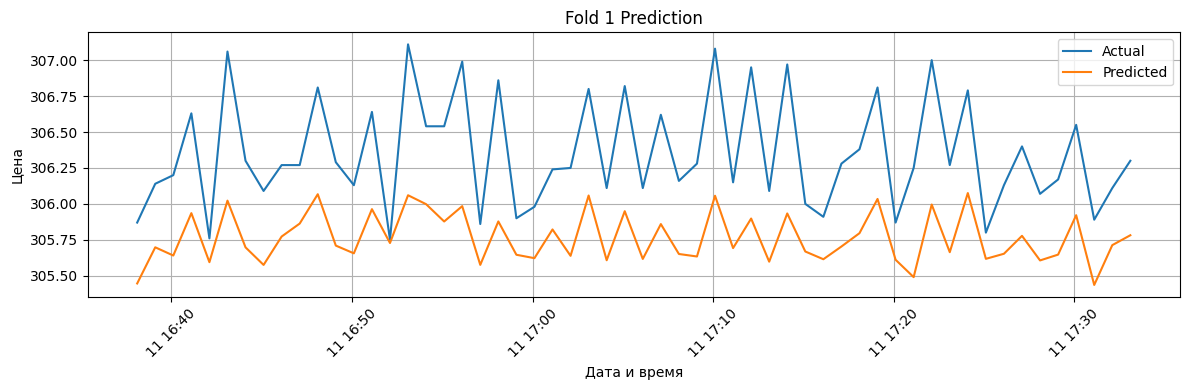

--- Обучение модели fold 2 ---


/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step
MSE fold 2: 0.105469

Сравнение фактических и предсказанных значений:
0: Факт = 306.1500, Прогноз = 306.3382
1: Факт = 306.5800, Прогноз = 306.5794
2: Факт = 306.1100, Прогноз = 306.3608
3: Факт = 306.0900, Прогноз = 306.3365
4: Факт = 306.2600, Прогноз = 306.3760
5: Факт = 305.9000, Прогноз = 306.1637
6: Факт = 305.7300, Прогноз = 306.4108
7: Факт = 306.1500, Прогноз = 306.3345
8: Факт = 306.6000, Прогноз = 306.5815
9: Факт = 305.8900, Прогноз = 306.3480
10: Факт = 307.1400, Прогноз = 306.7274
11: Факт = 306.6500, Прогноз = 306.5837
12: Факт = 306.0400, Прогноз = 306.3511
13: Факт = 306.2100, Прогноз = 306.4887
14: Факт = 305.5700, Прогноз = 306.2106
15: Факт = 306.1900, Прогноз = 306.3646
16: Факт = 306.9000, Прогноз = 306.7652
17: Факт = 305.5600, Прогноз = 306.4426
18: Факт = 306.2900, Прогноз = 306.3461
19: Факт = 305.9800, Прогноз = 306.3357
20: Факт = 305.6200, Прогноз = 306.2642
21: Факт = 306.6100, Прогноз = 306.6690
22: Факт = 306.6500, 

/tmp/ipykernel_1455668/3561127231.py:30: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')


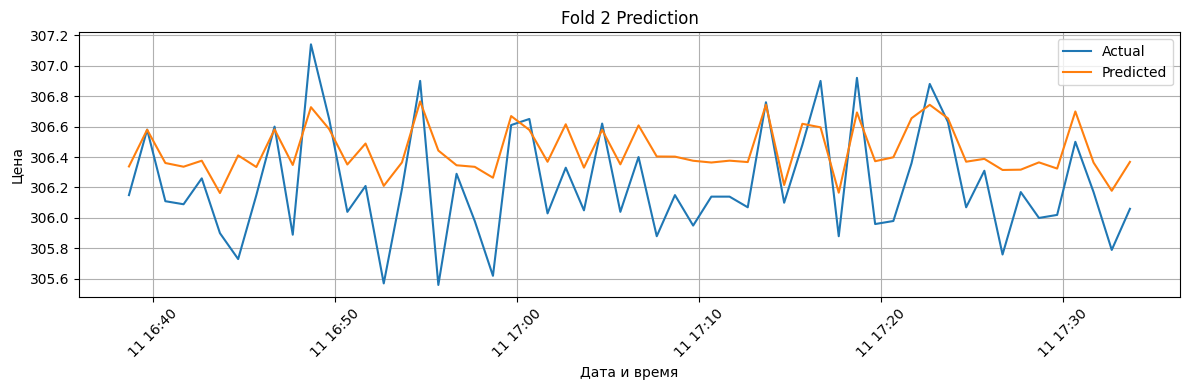

--- Обучение модели fold 3 ---


/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step
MSE fold 3: 0.129622

Сравнение фактических и предсказанных значений:
0: Факт = 306.5300, Прогноз = 306.3033
1: Факт = 306.1800, Прогноз = 305.9599
2: Факт = 306.6000, Прогноз = 306.1844
3: Факт = 306.2500, Прогноз = 306.0071
4: Факт = 307.0500, Прогноз = 306.3994
5: Факт = 306.3100, Прогноз = 306.2183
6: Факт = 306.0500, Прогноз = 305.9401
7: Факт = 306.0700, Прогноз = 305.9689
8: Факт = 306.1800, Прогноз = 305.9528
9: Факт = 305.7100, Прогноз = 305.8429
10: Факт = 305.7400, Прогноз = 305.9435
11: Факт = 306.1200, Прогноз = 305.9274
12: Факт = 306.3500, Прогноз = 306.0808
13: Факт = 305.6200, Прогноз = 305.8342
14: Факт = 306.9800, Прогноз = 306.4064
15: Факт = 306.8700, Прогноз = 306.2477
16: Факт = 306.1300, Прогноз = 306.0192
17: Факт = 306.6100, Прогноз = 306.1803
18: Факт = 306.1300, Прогноз = 305.8610
19: Факт = 307.1300, Прогноз = 306.3669
20: Факт = 306.1000, Прогноз = 305.9429
21: Факт = 306.1700, Прогноз = 306.0090
22: Факт = 306.3600, 

/tmp/ipykernel_1455668/3561127231.py:30: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')


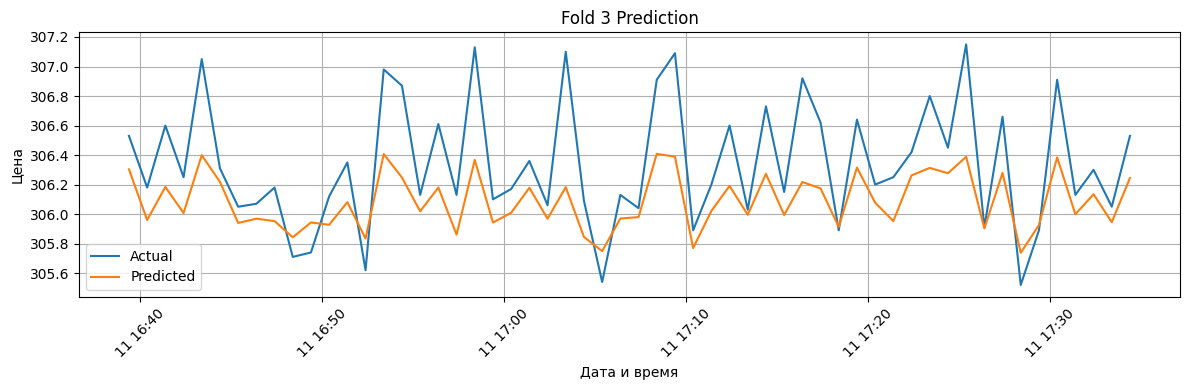

--- Обучение модели fold 4 ---


/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 260ms/step
MSE fold 4: 0.084920

Сравнение фактических и предсказанных значений:
0: Факт = 306.4500, Прогноз = 305.9832
1: Факт = 306.6700, Прогноз = 306.2995
2: Факт = 306.1700, Прогноз = 306.0935
3: Факт = 305.9200, Прогноз = 306.1131
4: Факт = 306.8300, Прогноз = 306.3913
5: Факт = 306.1700, Прогноз = 306.0344
6: Факт = 306.4900, Прогноз = 306.2433
7: Факт = 306.8200, Прогноз = 306.3857
8: Факт = 306.0400, Прогноз = 306.1288
9: Факт = 306.4100, Прогноз = 306.1513
10: Факт = 306.0900, Прогноз = 306.1338
11: Факт = 306.1300, Прогноз = 306.0829
12: Факт = 306.1400, Прогноз = 306.0949
13: Факт = 305.5300, Прогноз = 305.9206
14: Факт = 306.1900, Прогноз = 306.0555
15: Факт = 306.2000, Прогноз = 306.0567
16: Факт = 306.0700, Прогноз = 306.0864
17: Факт = 305.5100, Прогноз = 305.9002
18: Факт = 305.9100, Прогноз = 306.0478
19: Факт = 306.0600, Прогноз = 306.0134
20: Факт = 305.5300, Прогноз = 305.8890
21: Факт = 306.0500, Прогноз = 306.0891
22: Факт = 306.2500, 

/tmp/ipykernel_1455668/3561127231.py:30: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')


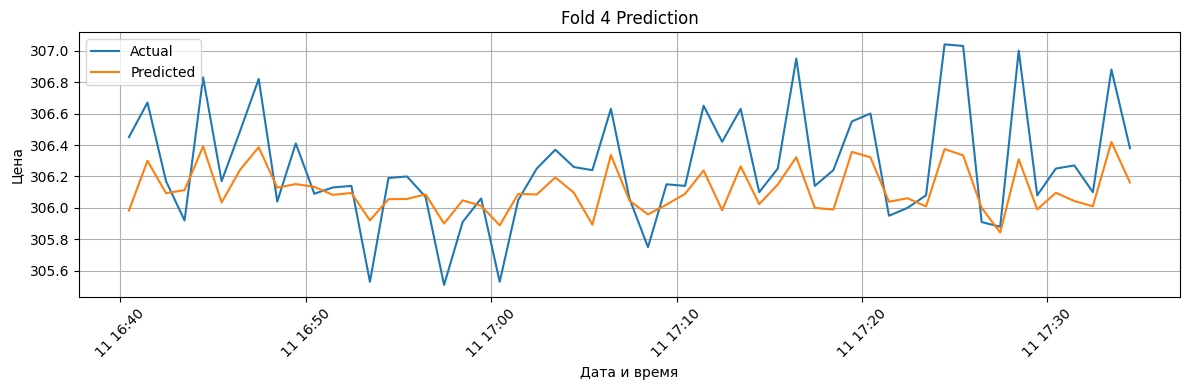


Выбрана лучшая модель с MSE: 0.084920
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
Сравнение фактических и предсказанных значений:
                     actual_close  predicted_close
datetime                                          
2025-05-11 07:25:00        306.59       306.346161
2025-05-11 07:28:00        306.71       306.345764
2025-05-11 07:29:00        306.60       306.342102
2025-05-11 07:34:00        306.67       306.306213
2025-05-11 07:38:00        306.56       306.283691
2025-05-11 07:41:00        306.64       306.268280
2025-05-11 07:43:00        306.46       306.260651
2025-05-11 07:44:00        306.30       306.256409
2025-05-11 07:49:00        306.60       306.220581
2025-05-11 08:01:00        306.83       306.246307
2025-05-11 08:04:00        306.99       306.271729
2025-05-11 08:05:00        307.00       306.283569
2025-05-11 08:19:00        306.78       306.409973
2025-05-11 08:25:00        307.08       306.408691
2025-05-11 08:27:00        307.01       306.414734
2025-05

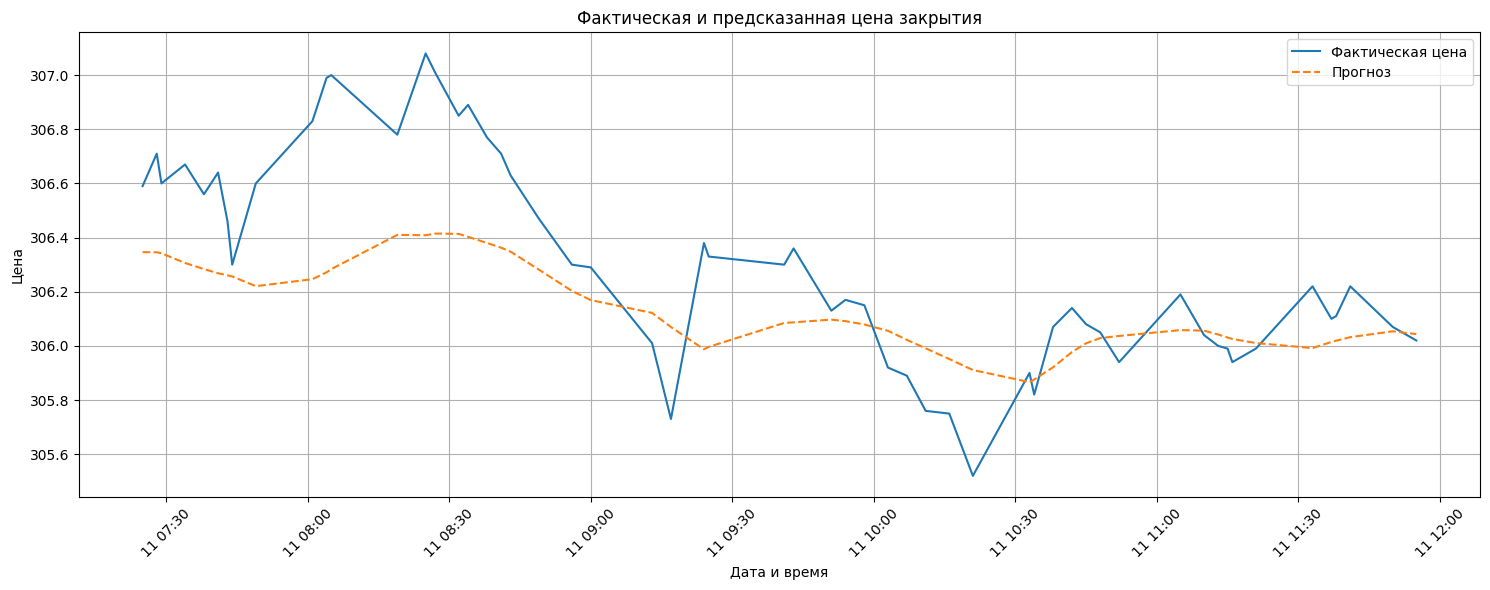


Среднеквадратичная ошибка (MSE): 0.088422


In [20]:
df = get_tinkoff_candles(TINKOFF_API_TOKEN, INSTRUMENT_FIGI, DAYS_HISTORY, CANDLE_TIMEFRAME)
diff_values, original_prices = prepare_data(df, FEATURE_COLUMN)
scaler = MinMaxScaler().fit(diff_values)
scaled = scaler.transform(diff_values)

X_all, y_all, all_times = split_sequences(scaled, N_STEPS_IN, N_STEPS_OUT, df.index)
X_all = X_all.reshape((X_all.shape[0], X_all.shape[1], 1))

X_trainval, X_test, y_trainval, y_test, times_trainval, times_test = train_test_split(
    X_all, y_all, all_times, test_size=0.2, shuffle=True, random_state=42
)
best_model = cross_validate_lstm(X_trainval, y_trainval, scaler, n_splits=4)
window_size = 30
final_test(
    best_model,     # обученная модель
    X_test,         # входы тестовой выборки
    y_test,         # правильные ответы (нормализованные)
    scaler,         # объект MinMaxScaler
    df,             # исходный DataFrame с колонками и datetime-индексом
    window_size,    # размер скользящего окна, который ты использовал при генерации X
    times_test
)


9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step


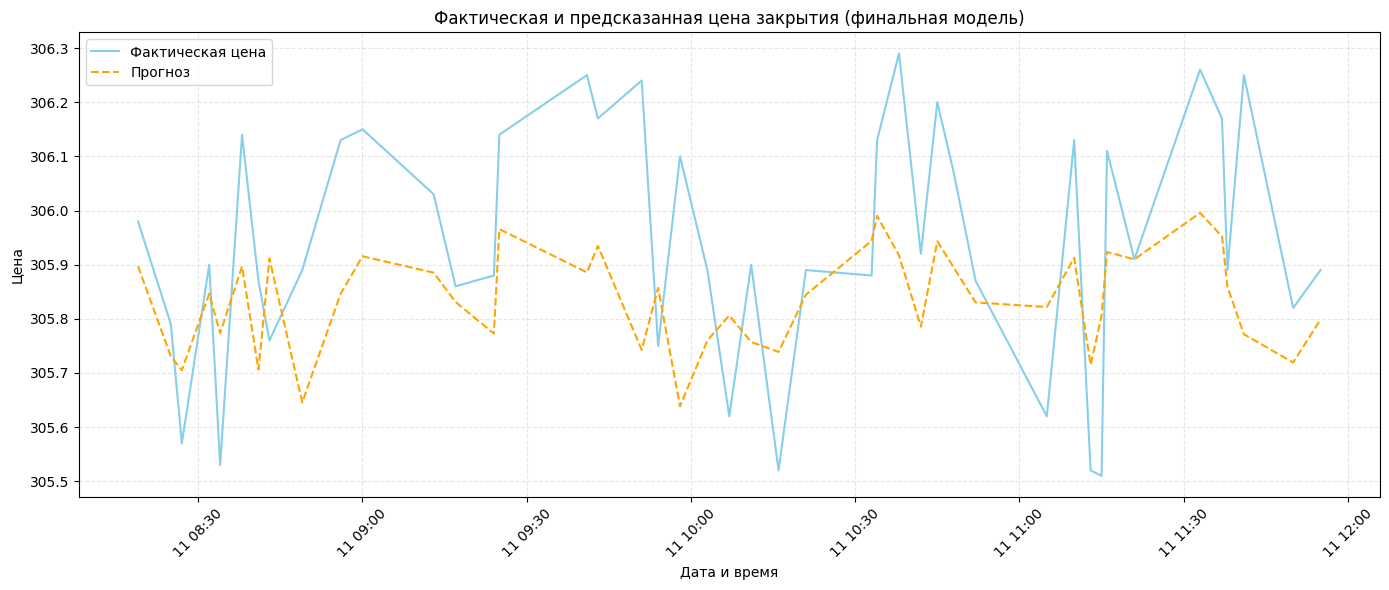

In [23]:
# Предсказание и обратное масштабирование
# Предсказание и обратное масштабирование
preds = best_model.predict(X_all)
preds_inv = scaler.inverse_transform(preds.reshape(-1, preds.shape[-1]))
y_test_inv = scaler.inverse_transform(y_trainval.reshape(-1, y_all.shape[-1]))

portion = 0.8
min_len = min(len(times_test), len(y_test_inv), len(preds_inv))

result_df = pd.DataFrame({
    'datetime': times_test[-min_len:],  # последние N значений
    'actual_close': y_test_inv.flatten()[-min_len:],
    'predicted_close': preds_inv.flatten()[-min_len:]
}).set_index('datetime')


# Сортировка по времени
result_df = result_df.sort_index()

# Отображаем только portion последних данных
portion_len = int(len(result_df) * portion)
plot_df = result_df.iloc[-portion_len:]

# Отображение
plt.figure(figsize=(14, 6))
plt.plot(plot_df.index, plot_df['actual_close'], label='Фактическая цена', color='skyblue')
plt.plot(plot_df.index, plot_df['predicted_close'], label='Прогноз', color='orange', linestyle='--')
plt.title('Фактическая и предсказанная цена закрытия (финальная модель)')
plt.xlabel('Дата и время')
plt.ylabel('Цена')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()